In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\bisha\Downloads\AirPassengers.csv")
df=df.rename(columns={'#Passengers':'y','Month':'ds'})
df.head()

,ds,y
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df['y_orig']=df['y']
df['y']=np.log(df['y'])

In [4]:
df.head()

,ds,y,y_orig
0,1949-01,4.718499,112
1,1949-02,4.770685,118
2,1949-03,4.882802,132
3,1949-04,4.859812,129
4,1949-05,4.795791,121


In [5]:
from prophet import Prophet
model=Prophet()
model.add_country_holidays(country_name='IND')
model.fit(df)

C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\holidays\countries\india.py:182: Warning: Requested Holidays are available only from 2001 to 2035.
  warnings.warn(warning_msg, Warning)
C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\holidays\countries\india.py:182: Warning: Requested Holidays are available only from 2001 to 2035.
  warnings.warn(warning_msg, Warning)
21:03:10 - cmdstanpy - INFO - Chain [1] start processing
21:03:10 - cmdstanpy - INFO - Chain [1] done processing


In [6]:
future_data=model.make_future_dataframe(periods=12,freq='M')

C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\prophet\forecaster.py:1872: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


In [7]:
forecast_data=model.predict(future_data)
forecast_data.tail()

C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\holidays\countries\india.py:182: Warning: Requested Holidays are available only from 2001 to 2035.
  warnings.warn(warning_msg, Warning)
C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\holidays\countries\india.py:182: Warning: Requested Holidays are available only from 2001 to 2035.
  warnings.warn(warning_msg, Warning)


,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,Ashura (estimated),Ashura (estimated)_lower,Ashura (estimated)_upper,Christmas,...,holidays,holidays_lower,holidays_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
151,1961-07-31,6.273484,6.436985,6.531576,6.261591,6.285318,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.211393,0.211393,0.211393,0.0,0.0,0.0,6.484878
152,1961-08-31,6.282664,6.315088,6.416535,6.268027,6.297709,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.082197,0.082197,0.082197,0.0,0.0,0.0,6.364861
153,1961-09-30,6.291548,6.156874,6.256585,6.274754,6.309776,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.084525,-0.084525,-0.084525,0.0,0.0,0.0,6.207023
154,1961-10-31,6.300727,6.024725,6.122254,6.280683,6.322566,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.226959,-0.226959,-0.226959,0.0,0.0,0.0,6.073769
155,1961-11-30,6.309611,6.165837,6.267717,6.286458,6.334693,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.093169,-0.093169,-0.093169,0.0,0.0,0.0,6.216442


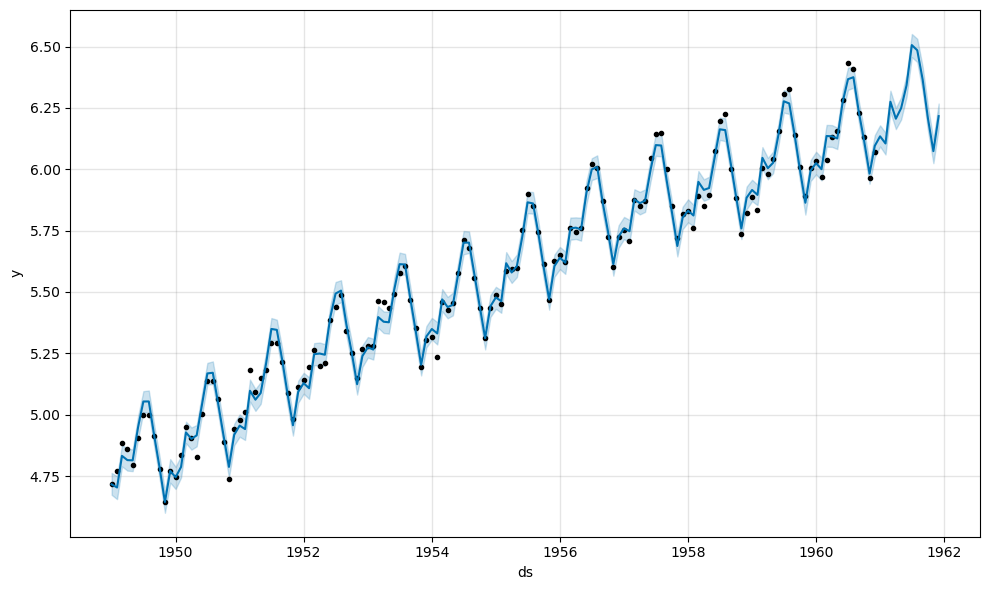

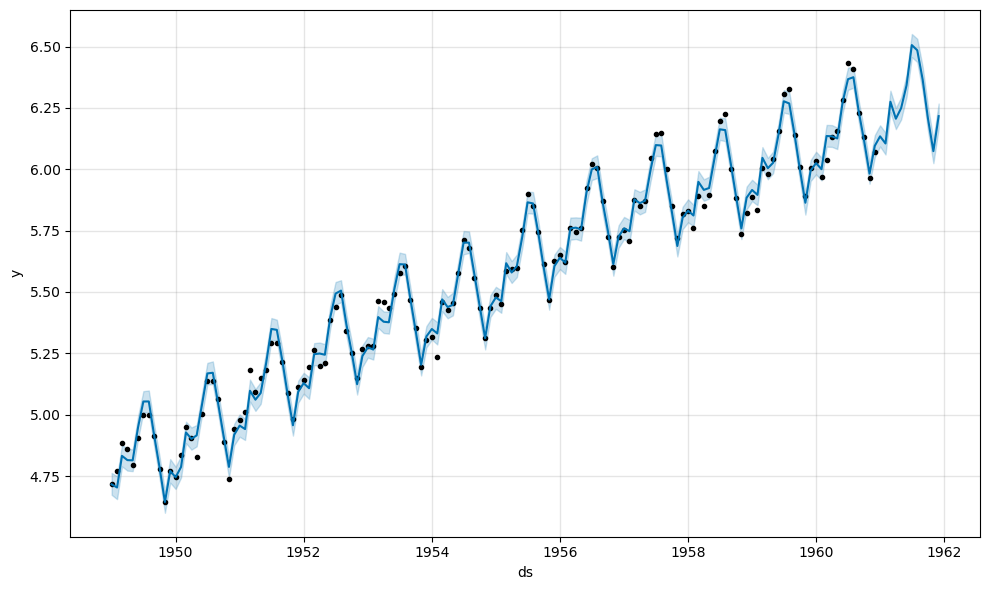

In [8]:
model.plot(forecast_data)

In [9]:
forecast_data['yhat']=np.exp(forecast_data['yhat'])
forecast_data['yhat_lower']=np.exp(forecast_data['yhat_lower'])
forecast_data['yhat_upper']=np.exp(forecast_data['yhat_upper'])

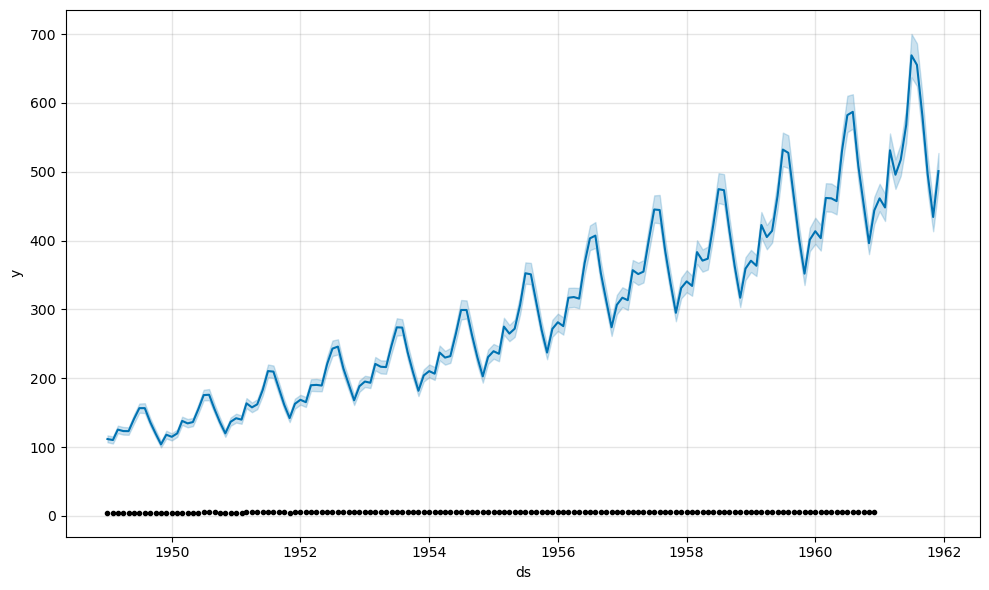

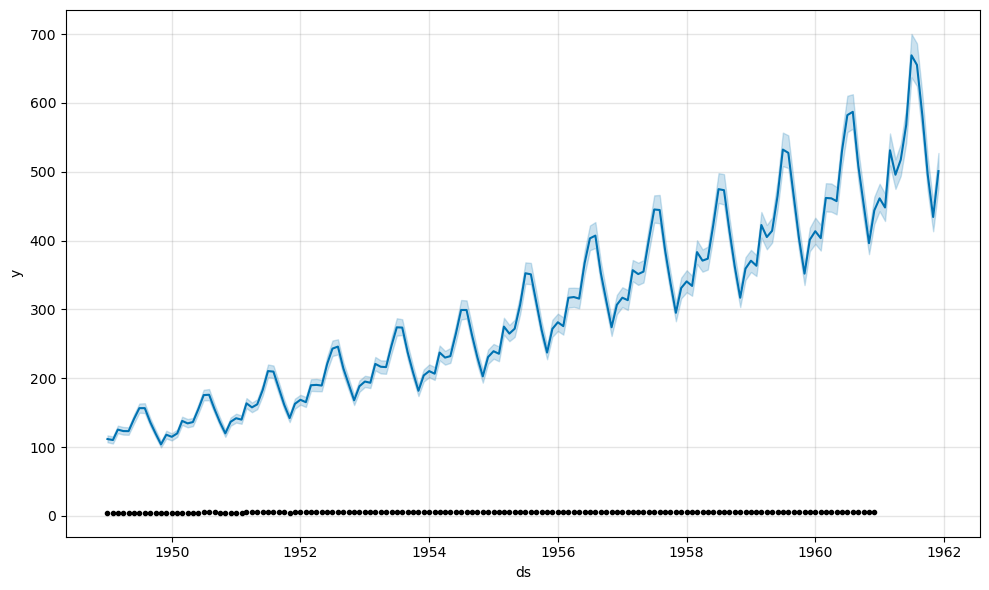

In [10]:
model.plot(forecast_data)